# Digit recognition
Offline training of the digit classifier (OpenCV SVM) and a k-NN reference, using MNIST. The trained SVM is saved to `../data/models/svm_digits.xml` and loaded by `digits.py` at startup. It only needs to be run once.

## 0. Preparation

In [1]:
# Check the OpenCV version (the lab environment uses 4.8.x)
import cv2
print("OpenCV should be 4.8.x Current version:", cv2.__version__)

# Numerical arrays, file paths and plots
import numpy as np
import os
import matplotlib.pyplot as plt

# Used only to download MNIST
from sklearn.datasets import fetch_openml

OpenCV should be 4.8.x Current version: 4.8.0


## 1. Loading MNIST
MNIST has 70000 handwritten digits of 28x28 pixels, white on black. It is not stored in the repository: it is downloaded from here.

In [2]:
# Download MNIST (the first time it can take a minute)
mnist = fetch_openml("mnist_784", version=1, as_frame=False)

# Every row has 784 values (28x28 pixels): reshape them into images
images = mnist.data.reshape(-1, 28, 28).astype(np.uint8)

# The labels come as text: convert them to integers (0-9)
labels = mnist.target.astype(np.int32)

print("Images:", images.shape, "Labels:", labels.shape)
print("Gray range:", images.min(), "-", images.max())

Images: (70000, 28, 28) Labels: (70000,)
Gray range: 0 - 255


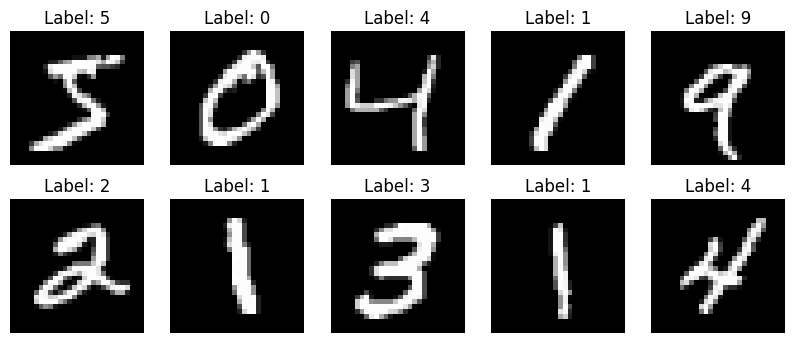

In [3]:
# Show the first 10 images to check that everything was loaded properly
# MNIST digits are WHITE on BLACK, the same as the canvas of main.py (strokes = 255, background = 0)
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for ax, img, label in zip(axes.ravel(), images[:10], labels[:10]):
    ax.imshow(img, cmap="gray")
    ax.set_title(f"Label: {label}")
    ax.axis("off")
plt.show()

## 2. Training, validation and test data
Standard MNIST split: the first 60000 images to train and the last 10000 to evaluate. Only a subset of the first 50000 is used for training so the SVM is fast. Images 50000-60000 are kept apart as a **validation set** to choose C and gamma. Since the hyperparameters are never chosen with the test set, the test accuracy is not biased: the test set is only used once, at the end.

In [4]:
# Number of images used to train (more images = slightly better, but slower and a much bigger model file)
n_train = 10000

# OpenCV needs: one sample per row, float32 values and int32 labels
# The gray levels are scaled from 0-255 to 0-1, so C and gamma work well
def to_samples(imgs):
    return imgs.reshape(len(imgs), -1).astype(np.float32) / 255.0

train_samples = to_samples(images[:n_train])
train_labels = labels[:n_train]

# Validation set: used ONLY to choose C and gamma (never to train the final model)
val_samples = to_samples(images[50000:60000])
val_labels = labels[50000:60000]

# The test images are never used to train or to tune, only to measure the final accuracy
test_samples = to_samples(images[60000:])
test_labels = labels[60000:]

print("Train:", train_samples.shape, "Validation:", val_samples.shape, "Test:", test_samples.shape)

Train: (10000, 784) Validation: (10000, 784) Test: (10000, 784)


## 3. SVM hyperparameters
Support Vector Machine with an **RBF kernel** applied directly to the pixels. Other kernels (linear, polynomial) were not compared here.

The RBF kernel has two hyperparameters, chosen with a small grid search on the **validation** set:
- **C**: penalty of the errors. Higher = fits the training data harder (risk of overfitting).
- **gamma**: width of the RBF kernel. Higher = more local decision boundaries.

To keep the search fast, each combination is trained on 5000 images and evaluated on 2000 validation images.

In [5]:
def create_svm(C, gamma):
    """C-support classifier with an RBF kernel."""
    svm = cv2.ml.SVM_create()
    svm.setType(cv2.ml.SVM_C_SVC)
    svm.setKernel(cv2.ml.SVM_RBF)
    svm.setC(C)
    svm.setGamma(gamma)
    # Stop after 1000 iterations OR when the improvement is smaller than 1e-6 (whatever happens first)
    svm.setTermCriteria((cv2.TERM_CRITERIA_MAX_ITER + cv2.TERM_CRITERIA_EPS, 1000, 1e-6))
    return svm

def accuracy(model, samples, true_labels):
    """Fraction of samples correctly classified, and the predictions."""
    _, pred = model.predict(samples)
    pred = pred.ravel().astype(np.int32)
    return np.mean(pred == true_labels), pred

# Grid search on the validation set (it can take a few minutes)
C_values = [1, 5, 10]
gamma_values = [0.01, 0.02, 0.05]

results = np.zeros((len(C_values), len(gamma_values)))
for i, C in enumerate(C_values):
    for j, gamma in enumerate(gamma_values):
        svm = create_svm(C, gamma)
        svm.train(train_samples[:5000], cv2.ml.ROW_SAMPLE, train_labels[:5000])
        results[i, j], _ = accuracy(svm, val_samples[:2000], val_labels[:2000])
        print(f"C = {C:>2}   gamma = {gamma:.2f}   validation accuracy: {results[i, j] * 100:.2f} %")

best_i, best_j = np.unravel_index(np.argmax(results), results.shape)
best_C, best_gamma = C_values[best_i], gamma_values[best_j]
print(f"\nBest: C = {best_C}, gamma = {best_gamma}")

C =  1   gamma = 0.01   validation accuracy: 95.35 %


C =  1   gamma = 0.02   validation accuracy: 95.75 %


C =  1   gamma = 0.05   validation accuracy: 95.70 %


C =  5   gamma = 0.01   validation accuracy: 95.70 %


C =  5   gamma = 0.02   validation accuracy: 96.25 %


C =  5   gamma = 0.05   validation accuracy: 95.85 %


C = 10   gamma = 0.01   validation accuracy: 95.60 %


C = 10   gamma = 0.02   validation accuracy: 96.25 %


C = 10   gamma = 0.05   validation accuracy: 95.85 %

Best: C = 5, gamma = 0.02


## 4. Final SVM
Trained with the best hyperparameters on the whole training subset. This is the classifier AirMath will use. The test set is used here for the first and only time.

In [6]:
# Train the final SVM 
svm = create_svm(best_C, best_gamma)
svm.train(train_samples, cv2.ml.ROW_SAMPLE, train_labels)

svm_val_accuracy, _ = accuracy(svm, val_samples, val_labels)
svm_accuracy, svm_pred = accuracy(svm, test_samples, test_labels)
print(f"SVM validation accuracy: {svm_val_accuracy * 100:.2f} %")
print(f"SVM test accuracy:       {svm_accuracy * 100:.2f} %")
print("Support vectors:", svm.getSupportVectors().shape[0])

SVM validation accuracy: 97.28 %
SVM test accuracy:       96.97 %
Support vectors: 4164


## 5. k-NN (reference)
It is only used to compare against the SVM in the report. It is not used in AirMath. It is trained on the same images as the SVM, so the comparison is fair.

In [7]:
# Create the k-Nearest Neighbours classifier and "train" it (it just stores the samples)
knn = cv2.ml.KNearest_create()
knn.train(train_samples, cv2.ml.ROW_SAMPLE, train_labels)

# Each test image takes the most common label among its 3 nearest training images
_, knn_pred, _, _ = knn.findNearest(test_samples, k=3)
knn_pred = knn_pred.ravel().astype(np.int32)
knn_accuracy = np.mean(knn_pred == test_labels)
print(f"k-NN accuracy: {knn_accuracy * 100:.2f} %")

k-NN accuracy: 94.63 %


## 6. SVM confusion matrix
Rows = true digit, columns = predicted digit. A perfect classifier would only have values on the diagonal; everything outside it is an error.

Digit 0: 98.78 %
Digit 1: 99.21 %
Digit 2: 97.19 %
Digit 3: 96.44 %
Digit 4: 97.66 %
Digit 5: 95.52 %
Digit 6: 98.02 %
Digit 7: 95.43 %
Digit 8: 96.82 %
Digit 9: 94.35 %

Most common mistakes:
  9 read as 4: 17 times
  7 read as 2: 17 times
  5 read as 3: 14 times
  3 read as 2: 11 times
  4 read as 9: 10 times


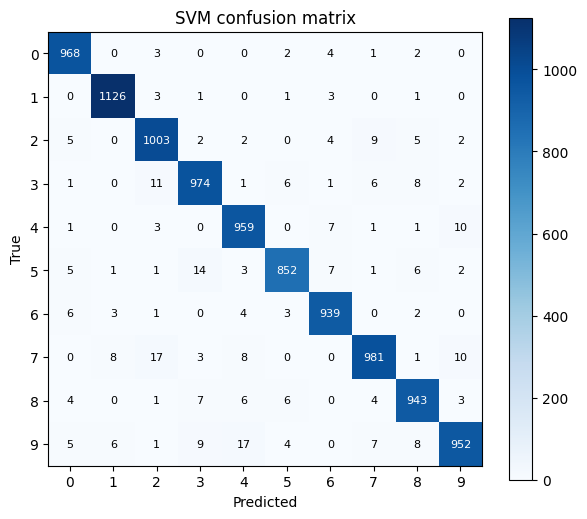

In [8]:
# Count how many times each real digit (row) was predicted as each digit (column)
confusion = np.zeros((10, 10), dtype=np.int32)
np.add.at(confusion, (test_labels, svm_pred), 1)

# Accuracy of every digit: correct predictions / number of test images of that digit
per_class = confusion.diagonal() / confusion.sum(axis=1)
for digit, acc in enumerate(per_class):
    print(f"Digit {digit}: {acc * 100:.2f} %")

# Most common mistakes (largest values outside the diagonal)
errors = confusion.copy()
np.fill_diagonal(errors, 0)
print("\nMost common mistakes:")
for idx in np.argsort(errors.ravel())[::-1][:5]:
    true_digit, pred_digit = divmod(idx, 10)
    print(f"  {true_digit} read as {pred_digit}: {errors[true_digit, pred_digit]} times")

# Plot it with the counts written inside every cell
plt.figure(figsize=(7, 6))
plt.imshow(confusion, cmap="Blues")
plt.colorbar()
for t in range(10):
    for p in range(10):
        color = "white" if confusion[t, p] > confusion.max() / 2 else "black"
        plt.text(p, t, confusion[t, p], ha="center", va="center", color=color, fontsize=8)
plt.xticks(range(10))
plt.yticks(range(10))
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("SVM confusion matrix")
plt.show()

### Misclassified examples
Test images of the 3 most common mistakes (one row per mistake). Some of them are ambiguous even for a person (a 9 with an open loop looks like a 4), but others are clear digits:
- Several **7s with a horizontal bar** in the middle are read as 2. This is the usual way of writing the 7 in Spain, and it is rare in MNIST (mostly American writers), so it can be a frequent problem in AirMath.
- Some 5s with a thin or open top part are read as 3.

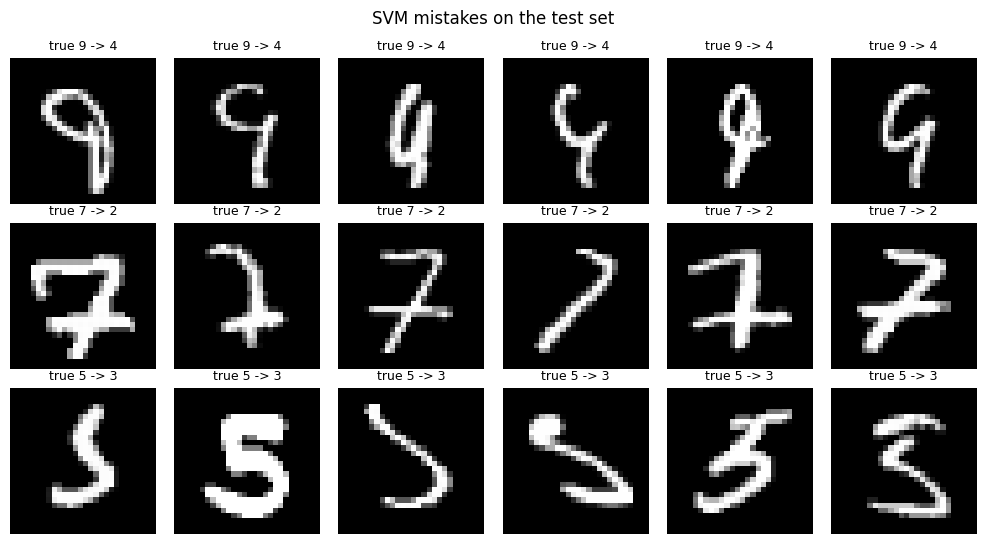

In [9]:
# The 3 most common mistakes (true digit, predicted digit), taken from the confusion matrix
top_mistakes = [divmod(idx, 10) for idx in np.argsort(errors.ravel())[::-1][:3]]
n_examples = 6

fig, axes = plt.subplots(len(top_mistakes), n_examples, figsize=(10, 5.5))
for row, (true_digit, pred_digit) in enumerate(top_mistakes):
    # Indices of the test images with this mistake
    wrong = np.where((test_labels == true_digit) & (svm_pred == pred_digit))[0][:n_examples]
    for col in range(n_examples):
        ax = axes[row, col]
        ax.axis("off")
        if col < len(wrong):
            ax.imshow(images[60000 + wrong[col]], cmap="gray")
            ax.set_title(f"true {true_digit} -> {pred_digit}", fontsize=9)
plt.suptitle("SVM mistakes on the test set")
plt.tight_layout()
plt.show()

### Results
*(Results with `n_train = 10000`. If the training data or the grid change, these numbers have to be updated.)*

| Classifier | Test accuracy |
|---|---|
| SVM (RBF, C = 5, gamma = 0.02) | **96.97 %** |
| k-NN (k = 3) | 94.63 % |

- The SVM is better than k-NN by about 2.3 points with the same training images, so it is the classifier used in AirMath.
- The best recognised digit is the **1** (99.2 %) and the worst is the **9** (94.4 %).
- The most common mistakes are 7 → 2 and 9 → 4 (17 times each), followed by 5 → 3 (14 times). They are pairs of digits with a similar shape, and they will probably be confused even more when the digits are drawn in the air, where the strokes are less precise.

## 7. Saving the model
`digits.py` loads this file at startup, so there is no need to train again.

In [10]:
# Save the trained SVM
os.makedirs("../data/models", exist_ok=True)
svm.save("../data/models/svm_digits.xml")

# Check that it can be loaded again and gives exactly the same accuracy
svm_loaded = cv2.ml.SVM_load("../data/models/svm_digits.xml")
check_accuracy, _ = accuracy(svm_loaded, test_samples, test_labels)
print(f"Loaded SVM accuracy: {check_accuracy * 100:.2f} %")

Loaded SVM accuracy: 96.97 %
